In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression, SGDClassifier, ElasticNet, Lasso, RidgeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss, make_scorer
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.preprocessing import PolynomialFeatures
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.utils import shuffle

In [3]:
train_df=pd.read_csv("Train.csv")

c:\Users\user\Anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='PURCHASE_VALUE', ylabel='Density'>

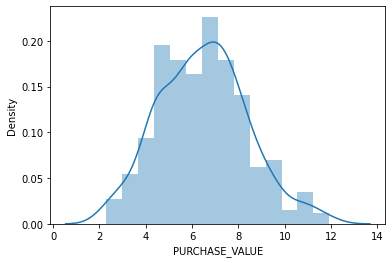

In [6]:
sns.distplot(np.log(train_df.PURCHASE_VALUE))

c:\Users\user\Anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='USER_INCOME', ylabel='Density'>

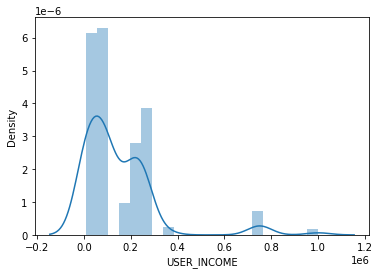

In [9]:
sns.distplot(train_df.USER_INCOME)

c:\Users\user\Anaconda3\lib\site-packages\seaborn\distributions.py:2619: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)


<AxesSubplot:xlabel='USER_HOUSEHOLD', ylabel='Density'>

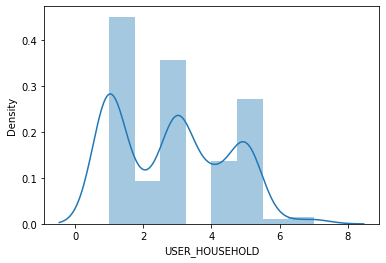

In [10]:
sns.distplot(train_df.USER_HOUSEHOLD)

In [5]:
pd.cut(duplicates="drop")

TypeError: cut() missing 2 required positional arguments: 'x' and 'bins'

In [132]:
train_df=pd.read_csv("Train.csv")
extra=pd.read_csv("extra_data.csv")

log_PURCHASE_VALUE=np.log(train_df.PURCHASE_VALUE)
bins=[np.quantile(log_PURCHASE_VALUE, i) for i in np.linspace(0,1,14)]
train_df["Var_1"]=pd.cut(log_PURCHASE_VALUE, bins, duplicates='drop').astype("object")

freq_dict = pd.concat([extra.MERCHANT_NAME, train_df.MERCHANT_NAME], axis=0).reset_index(drop=True).value_counts().to_dict()
category={j:f"cat_{i}" for i,j in enumerate(np.unique(list(freq_dict.values())))}
MERCHANT_NAME_code={key:category[val] for key, val in freq_dict.items()}
#train_df["Var_2"]=train_df.MERCHANT_NAME.map(MERCHANT_NAME_code)

per_freq_dict = pd.concat([extra.MERCHANT_NAME, train_df.MERCHANT_NAME], axis=0).reset_index(drop=True).value_counts(normalize=True).to_dict()
#train_df["Var_3"]=train_df.MERCHANT_NAME.map(per_freq_dict)

true_columns=["MERCHANT_CATEGORIZED_AT","PURCHASED_AT","Transaction_ID","USER_AGE","USER_GENDER","USER_ID","PURCHASE_VALUE"]
df=train_df.drop(true_columns, axis=1)
val_columns=[i for i in train_df.MERCHANT_CATEGORIZED_AS.unique() if (train_df.MERCHANT_CATEGORIZED_AS[train_df.MERCHANT_CATEGORIZED_AS==i].shape[0]/train_df.shape[0]>0.01)]
df=df[df.MERCHANT_CATEGORIZED_AS.isin(val_columns)]

cat_codes={
    False:1,
    True:0,
    "Male":1,
    "Female":0,
}
#df.USER_GENDER=df.USER_GENDER.map(cat_codes)
df.IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY=df.IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY.map(cat_codes)
var_enc=LabelEncoder()
df.Var_1=var_enc.fit_transform(df.Var_1)


In [139]:
X_train, X_test, y_train, y_test=train_test_split(df.drop(["MERCHANT_CATEGORIZED_AS"], axis=1), df.MERCHANT_CATEGORIZED_AS, test_size=.2, random_state=25)

In [140]:
# mask=[]
# for i in train_df.MERCHANT_CATEGORIZED_AS:
#     cdt=False
#     for j in val_columns:
#         if i==j:
#             cdt=True
#     mask.append(cdt)

# train_df[mask]

In [141]:
X_train

,MERCHANT_NAME,IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY,USER_HOUSEHOLD,USER_INCOME,Var_1
176,PAYTECH -THE JUNCTION MALL,1,5,750000,1
151,BAABAX EXPRESS LIMITED,1,2,10000,7
181,FAHARI RETIREMENT PLAN,0,1,250000,10
156,DENIS OTIENO,0,1,85000,9
361,MIRIAM MUNGAI,0,1,10000,7
...,...,...,...,...,...
259,BETHSHEBA NYAUNDI,0,2,10000,1
321,PETER KENDA,0,3,85000,1
146,ENVY VIVA CORPORATE,1,1,85000,2
322,PIZZA IN BELLEVUE,1,1,85000,6


In [163]:
def make_model(df):
    numerical_features=df.select_dtypes(["float","int"]).columns
    categorical_features=df.select_dtypes("object").columns

    numerical_pipeline=make_pipeline(StandardScaler())
    categorical_pipeline=make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown='ignore'))

    process=make_column_transformer((numerical_pipeline, ["USER_HOUSEHOLD","USER_INCOME"]), (categorical_pipeline, categorical_features))


    model=make_pipeline(process,MLPClassifier(activation="tanh", max_iter=150,random_state=121, alpha=0.05, solver="lbfgs"))
    
    return model

In [164]:
model=make_model(X_train)

In [165]:
model.fit(X_train, y_train)
predict=model.predict(X_test)
print(classification_report(y_test, predict))
proba=model.predict_proba(X_test)
print(f"Log_loss:{log_loss(y_test, proba)}")

                  precision    recall  f1-score   support

    Bills & Fees       0.59      0.81      0.68        16
     Data & WiFi       1.00      1.00      1.00         4
  Emergency fund       0.00      0.00      0.00         3
Family & Friends       1.00      0.62      0.77         8
       Going out       0.25      0.11      0.15         9
       Groceries       0.40      0.50      0.44         8
          Health       1.00      0.50      0.67         2
  Loan Repayment       0.00      0.00      0.00         2
   Miscellaneous       0.56      0.83      0.67        12
        Shopping       0.00      0.00      0.00         4
Transport & Fuel       0.40      0.67      0.50         6

        accuracy                           0.57        74
       macro avg       0.47      0.46      0.44        74
    weighted avg       0.51      0.57      0.52        74

Log_loss:1.6691275332950164


c:\Users\user\Anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:549: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
c:\Users\user\Anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\user\Anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(aver

In [166]:
score=make_scorer(log_loss)

In [167]:
hyper_params = {
    'mlpclassifier__hidden_layer_sizes': [(50,50,50), (50,100,50), (100,)],
    'mlpclassifier__activation': ['tanh', 'relu'],
    'mlpclassifier__solver': ['sgd', 'adam'],
    'mlpclassifier__alpha': [0.0001, 0.05],
    'mlpclassifier__learning_rate': ['constant','adaptive'],
}

In [168]:
grid=GridSearchCV(model, hyper_params, cv=4)

grid.fit(X_train, y_train)
predict=grid.predict(X_test)
print(classification_report(y_test, predict))
proba=grid.predict_proba(X_test)
print(f"Log_loss:{log_loss(y_test, proba)}")

c:\Users\user\Anaconda3\lib\site-packages\sklearn\model_selection\_split.py:680: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=4.
  UserWarning,
c:\Users\user\Anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:696: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  ConvergenceWarning,
c:\Users\user\Anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:696: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  ConvergenceWarning,
c:\Users\user\Anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:696: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  ConvergenceWarning,
c:\Users\user\Anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:696: Conve

                  precision    recall  f1-score   support

    Bills & Fees       0.80      0.75      0.77        16
     Data & WiFi       1.00      1.00      1.00         4
  Emergency fund       0.25      0.33      0.29         3
Family & Friends       1.00      0.62      0.77         8
       Going out       0.00      0.00      0.00         9
       Groceries       0.57      0.50      0.53         8
          Health       0.25      0.50      0.33         2
  Loan Repayment       0.00      0.00      0.00         2
   Miscellaneous       0.56      0.83      0.67        12
        Shopping       0.00      0.00      0.00         4
Transport & Fuel       0.33      0.17      0.22         6

        accuracy                           0.51        74
       macro avg       0.43      0.43      0.42        74
    weighted avg       0.53      0.51      0.51        74

Log_loss:1.9624858734091126


c:\Users\user\Anaconda3\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:696: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  ConvergenceWarning,
c:\Users\user\Anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\user\Anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\user\Anaconda3\lib\site-packages\sklearn\metrics\_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill

In [169]:
print(grid.best_params_)

{'mlpclassifier__activation': 'relu', 'mlpclassifier__alpha': 0.05, 'mlpclassifier__hidden_layer_sizes': (50, 100, 50), 'mlpclassifier__learning_rate': 'constant', 'mlpclassifier__solver': 'adam'}


In [17]:
print(grid.best_score_)

0.5254072565716401


In [18]:
SCORERS.keys()

dict_keys(['explained_variance', 'r2', 'max_error', 'neg_median_absolute_error', 'neg_mean_absolute_error', 'neg_mean_absolute_percentage_error', 'neg_mean_squared_error', 'neg_mean_squared_log_error', 'neg_root_mean_squared_error', 'neg_mean_poisson_deviance', 'neg_mean_gamma_deviance', 'accuracy', 'top_k_accuracy', 'roc_auc', 'roc_auc_ovr', 'roc_auc_ovo', 'roc_auc_ovr_weighted', 'roc_auc_ovo_weighted', 'balanced_accuracy', 'average_precision', 'neg_log_loss', 'neg_brier_score', 'adjusted_rand_score', 'rand_score', 'homogeneity_score', 'completeness_score', 'v_measure_score', 'mutual_info_score', 'adjusted_mutual_info_score', 'normalized_mutual_info_score', 'fowlkes_mallows_score', 'precision', 'precision_macro', 'precision_micro', 'precision_samples', 'precision_weighted', 'recall', 'recall_macro', 'recall_micro', 'recall_samples', 'recall_weighted', 'f1', 'f1_macro', 'f1_micro', 'f1_samples', 'f1_weighted', 'jaccard', 'jaccard_macro', 'jaccard_micro', 'jaccard_samples', 'jaccard_wei

In [170]:
test_df=pd.read_csv("Test.csv")
test_df["Var_1"]=pd.cut(np.log(test_df.PURCHASE_VALUE), bins, duplicates='drop')
test_df.IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY=test_df.IS_PURCHASE_PAID_VIA_MPESA_SEND_MONEY.map(cat_codes)
# test_df["Var_2"]=test_df.MERCHANT_NAME.map(MERCHANT_NAME_code)
# test_df["Var_3"]=test_df.MERCHANT_NAME.map(per_freq_dict)
test_df.Var_1=var_enc.fit_transform(test_df.Var_1)
test_df.drop(true_columns, axis=1, inplace=True)
predictions=pd.DataFrame(model.predict_proba(test_df), columns=sorted(df.MERCHANT_CATEGORIZED_AS.unique()))
ss=pd.read_csv("SampleSubmission.csv")
for column in predictions.columns:
    ss[column]=predictions[column]

ss.head()

,Transaction_ID,Bills & Fees,Data & WiFi,Education,Emergency fund,Family & Friends,Going out,Groceries,Health,Loan Repayment,Miscellaneous,Rent / Mortgage,Shopping,Transport & Fuel
0,ID_00x9h2yx,0.026074,0.053574,0,0.463533,0.037476,0.036546,0.131812,0.002799,0.006992,0.003837,0,0.061016,0.176341
1,ID_01db594f,0.001204,0.000304,0,0.001012,0.000862,0.990341,0.001843,0.000091,0.000297,0.003323,0,0.000448,0.000273
2,ID_07pm99no,0.000566,0.000227,0,0.000416,0.000610,0.000651,0.001547,0.000098,0.000167,0.995127,0,0.000221,0.000370
3,ID_09jryhkd,0.408199,0.002179,0,0.012145,0.029234,0.018128,0.008571,0.000841,0.002261,0.455619,0,0.055877,0.006947
4,ID_0ccv924c,0.944291,0.005781,0,0.000949,0.017177,0.005901,0.000350,0.000542,0.000392,0.006299,0,0.014453,0.003863


In [ ]:
ss.to_csv("submission_34.csv", index=False)